# 04 · Interpretability and robustness: Grad-CAM + test with field images

A macro F1 of ~0.98 on the PlantVillage test set does not say whether the model is useful outside the laboratory. This notebook tries to answer two questions:

1. **What does the model focus on?** With Grad-CAM we see whether it looks at the leaf or at the uniform background of the laboratory photos.
2. **Does it generalize to other sources?** The same model is evaluated, without retraining, on images from another dataset (PlantDoc: leaves cropped from image search engines, with very different backgrounds, lighting, and scales).

**Model used:** the one from the final configuration of notebook 03 (frozen MobileNetV3-Small plus a dense head, trained on **all** of train with `CW_POWER=0.5`), loaded from `models/`. Nothing is retrained: this notebook only analyzes the already trained model.

## 1. Setup and model loading

The full model saved by notebook 03 is loaded and split into its two parts: the backbone (the feature extractor) and the head (the classifier). Grad-CAM needs the last convolutional layer of the backbone, which produces an activation map of 7x7 regions with 576 channels right before the global pooling.

In [1]:
import os
import sys
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

ROOT = os.path.abspath("..")
sys.path.insert(0, ROOT)

import tensorflow as tf
from tensorflow import keras
from sklearn.metrics import f1_score

from src.data import load_splits

SEED = 42
rng = np.random.default_rng(SEED)
IMG_SIZE = (224, 224)  # (ancho, alto)
plt.rcParams["figure.dpi"] = 110

# Notebook 03 saves the full model as "<experiment>_full.keras"; since the experiment
# without a subset already ends in "_full", the file ends up with "_full_full".
MODEL_NAME = "tl_mobilenetv3small_224_cw0.5_full_full.keras"

models_dir = os.path.join(ROOT, "models")
print("Available models:", os.listdir(models_dir))

Available models: ['baseline_cw_128_subset.keras', 'baseline_nocw_128_subset.keras', 'tl_mobilenetv3small_224_cw0.0_full_full.keras', 'tl_mobilenetv3small_224_cw0.0_subset_full.keras', 'tl_mobilenetv3small_224_cw0.5_full_full.keras', 'tl_mobilenetv3small_224_cw0.5_subset_full.keras']


In [2]:
full_model = keras.models.load_model(os.path.join(models_dir, MODEL_NAME))

subs = [l for l in full_model.layers if isinstance(l, keras.Model)]
head = next(l for l in subs if l.name == "head")
backbone = next(l for l in subs if l.name != "head")

def _is_4d(layer):
    try:
        return len(layer.output.shape) == 4
    except Exception:
        return False

# Last layer that produces a 4D activation map: right before the global pooling
conv_layer = [l for l in backbone.layers if _is_4d(l)][-1]
conv_model = keras.Model(backbone.inputs, conv_layer.output)
print("Layer used for Grad-CAM:", conv_layer.name, conv_layer.output.shape)

Layer used for Grad-CAM: activation_53 (None, 7, 7, 576)


## 2. Helper functions

- **Grad-CAM:** for a given class, it computes which regions of the last activation map (7x7) contribute most to its score; that map is enlarged and overlaid on the image as a heat map. It is computed on the class **logit** (the score before the softmax) and not on its probability: with very confident predictions, the softmax gradient flattens out and produces empty maps.
- **Manual global average:** since the backbone is frozen, its global pooling is reproduced by hand (`reduce_mean`), which is exactly what the backbone does, so that gradients can be taken through it. The check cell confirms that both results match.

In [3]:
def to_input(pil_img):
    # Mismo preprocesado que en la extracción de features (03)
    return np.asarray(pil_img.convert("RGB").resize(IMG_SIZE), dtype=np.uint8)

last = head.layers[-1]                      # Dense con softmax
W, b = last.get_weights()
penult = keras.Model(head.inputs, head.layers[-2].output)

def gradcam(arr, class_idx=None):
    x = tf.convert_to_tensor(arr[None].astype(np.float32))
    with tf.GradientTape() as tape:
        conv_out = conv_model(x, training=False)
        tape.watch(conv_out)
        feats = tf.reduce_mean(conv_out, axis=(1, 2))
        logits = tf.matmul(penult(feats, training=False), W) + b
        if class_idx is None:
            class_idx = int(tf.argmax(logits[0]))
        score = logits[:, class_idx]
    grads = tape.gradient(score, conv_out)
    w = tf.reduce_mean(grads, axis=(1, 2))
    cam = tf.nn.relu(tf.reduce_sum(conv_out * w[:, None, None, :], axis=-1))[0].numpy()
    cam = cam / (cam.max() + 1e-8)
    return cam, class_idx, tf.nn.softmax(logits)[0].numpy()

def overlay(arr, cam, alpha=0.45):
    cam_up = np.asarray(
        Image.fromarray(np.uint8(255 * cam)).resize(IMG_SIZE, Image.BILINEAR),
        dtype=np.float32,
    ) / 255.0
    heat = plt.get_cmap("jet")(cam_up)[..., :3]
    return np.clip((1 - alpha) * (arr / 255.0) + alpha * heat, 0, 1), cam_up

def short(name):
    return name.replace("___", " / ")

In [4]:
# Sanity check: the manual average must match the backbone output
x = tf.convert_to_tensor(np.zeros((1, IMG_SIZE[1], IMG_SIZE[0], 3), dtype=np.float32) + 128)
diff = np.abs(
    tf.reduce_mean(conv_model(x, training=False), axis=(1, 2)).numpy() - backbone(x, training=False).numpy()
).max()
print(f"Maximum difference between manual pooling and backbone: {diff:.2e}  (should be ~0)")

Maximum difference between manual pooling and backbone: 0.00e+00  (should be ~0)


## 3. Grad-CAM on the PlantVillage test set

A random sample of 400 images from the test set (the same split as in the previous notebooks) is taken and the predictions are computed: accuracy on the sample is 0.980, with 392 correct predictions and 8 errors. Grad-CAM maps are then shown for correct predictions and for errors. In each pair of images, the one on the left is the original and the one on the right is the heat map; for errors, the map is computed for the predicted class.

In [5]:
train, val, test = load_splits()
label_feat = test.features["label"]
id2name = dict(enumerate(label_feat.names))
name2id = {v: k for k, v in id2name.items()}
n_classes = len(id2name)
bg_id = name2id["Background_without_leaves"]

N = 400
sample_idx = rng.choice(len(test), size=N, replace=False)
arrs = np.stack([to_input(test[int(i)]["image"]) for i in sample_idx])
y_true = np.array([test[int(i)]["label"] for i in sample_idx])

probs = full_model.predict(arrs.astype(np.float32), batch_size=64, verbose=0)
y_pred = probs.argmax(1)
print(f"Accuracy on the sample of {N}: {(y_pred == y_true).mean():.3f}")

Accuracy on the sample of 400: 0.980


correct predictions: 392 | mistakes: 8


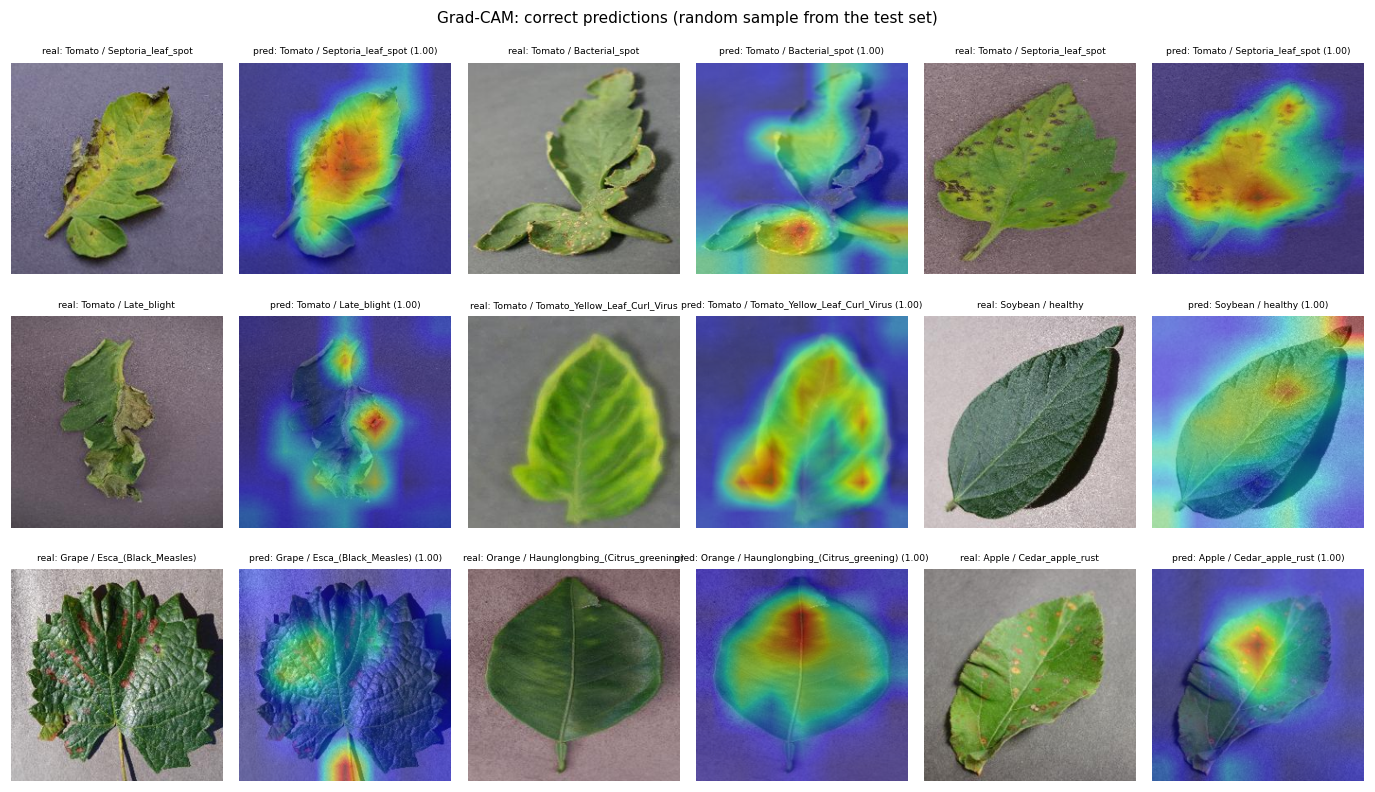

In [6]:
def show_cams(indices, arrs, y_true, y_pred, probs, ncols=3, title=None):
    n = len(indices)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols * 2, figsize=(ncols * 4.2, nrows * 2.5))
    axes = np.atleast_2d(axes)
    for ax in axes.ravel():
        ax.axis("off")
    for k, i in enumerate(indices):
        r, c = divmod(k, ncols)
        cam, _, _ = gradcam(arrs[i], class_idx=int(y_pred[i]))
        ov, _ = overlay(arrs[i], cam)
        axes[r, 2 * c].imshow(arrs[i])
        axes[r, 2 * c + 1].imshow(ov)
        axes[r, 2 * c].set_title(f"real: {short(id2name[int(y_true[i])])}", fontsize=6)
        axes[r, 2 * c + 1].set_title(
            f"pred: {short(id2name[int(y_pred[i])])} ({probs[i].max():.2f})", fontsize=6
        )
    if title:
        fig.suptitle(title, fontsize=10)
    plt.tight_layout()
    plt.show()

ok = np.where(y_pred == y_true)[0]
bad = np.where(y_pred != y_true)[0]
print("correct predictions:", len(ok), "| mistakes:", len(bad))

show_cams(rng.choice(ok, size=9, replace=False), arrs, y_true, y_pred, probs,
          title="Grad-CAM: correct predictions (random sample from the test set)")

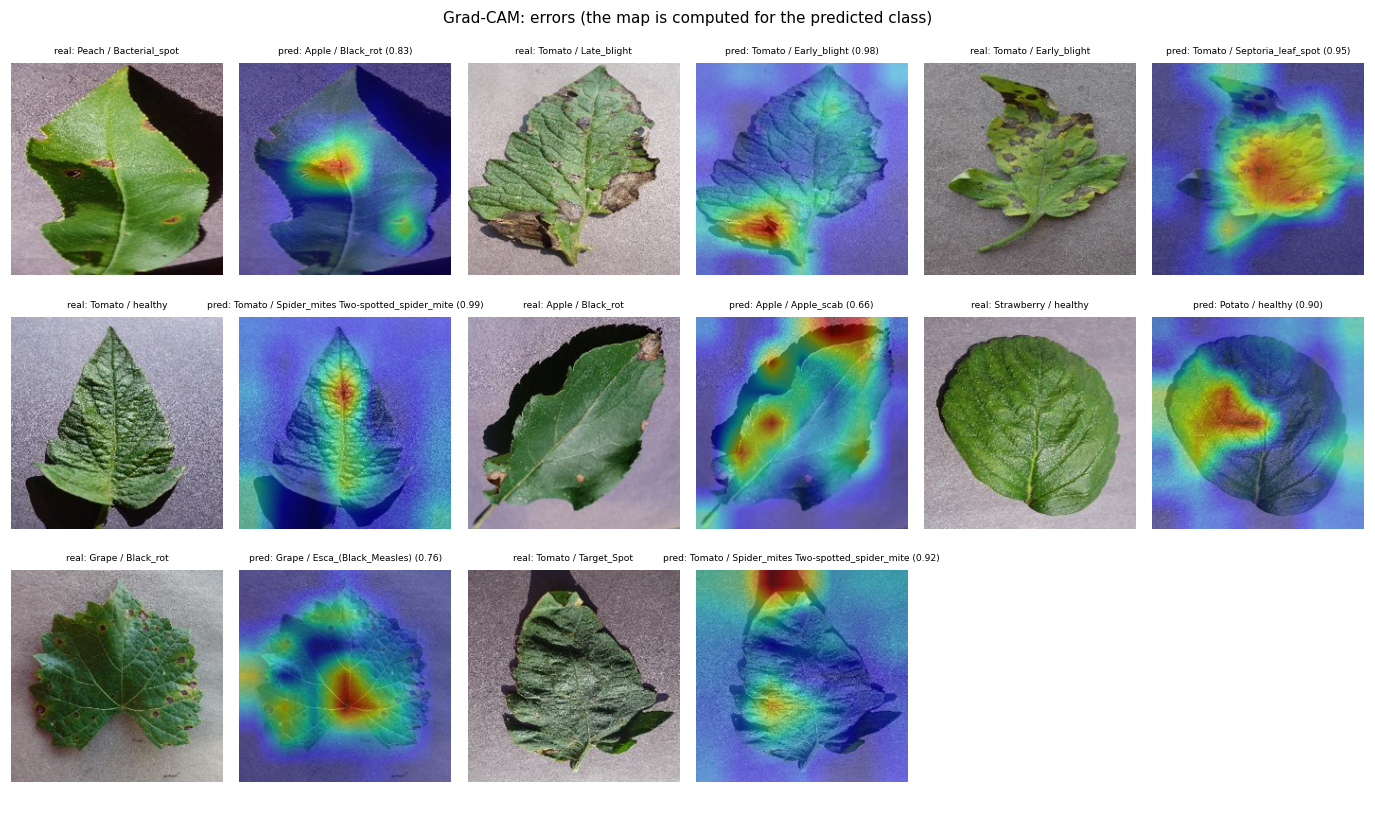

In [7]:
if len(bad) > 0:
    show_cams(rng.choice(bad, size=min(9, len(bad)), replace=False), arrs, y_true, y_pred, probs,
              title="Grad-CAM: errors (the map is computed for the predicted class)")

### 3.1 How much does the model look at the leaf versus the background? (heuristic)

There are no leaf masks, so they are approximated: the PlantVillage background is gray and weakly saturated, while the leaf has color. Pixels with saturation above a threshold (`SAT_THRESHOLD = 0.25`) are marked as "leaf", and the share of the Grad-CAM activation that falls there is measured, compared with the area that this "leaf" occupies. Before computing it, the masks of six images are shown to check that they make sense.

- **Ratio > 1:** the model concentrates on the leaf more than would be expected by chance.
- **Ratio ≈ 1:** it spreads its attention without distinguishing leaf from background.

This is a **rough approximation**: it depends on the color threshold and does not distinguish lesions from healthy tissue.

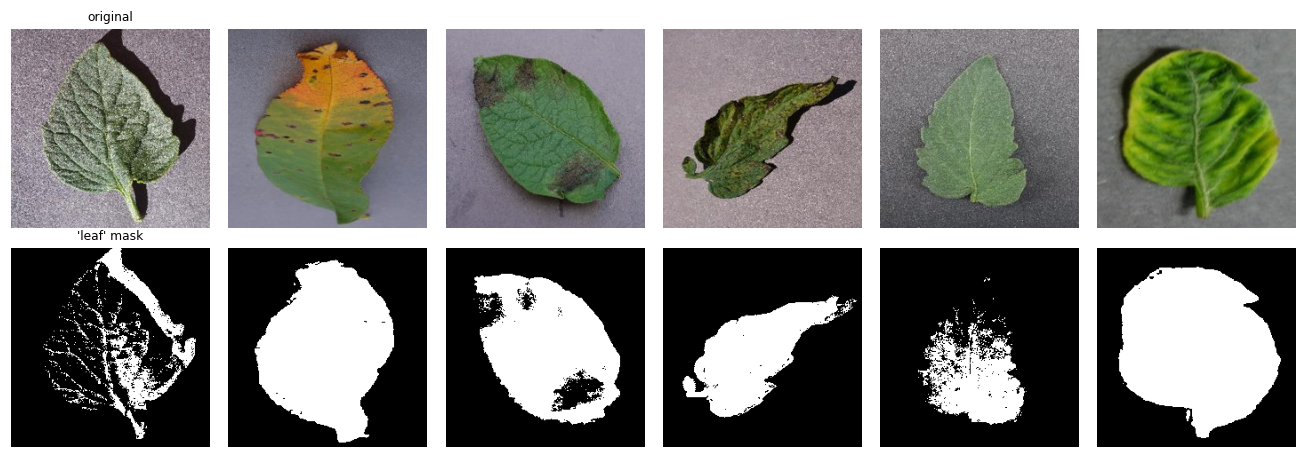

In [ ]:
SAT_THRESHOLD = 0.25

def leaf_mask(arr_uint8, thr=SAT_THRESHOLD):
    hsv = np.asarray(Image.fromarray(arr_uint8).convert("HSV"), dtype=np.float32) / 255.0
    return hsv[..., 1] > thr

# Visual revision of mask
show = rng.choice(np.where(y_true != bg_id)[0], size=6, replace=False)
fig, axes = plt.subplots(2, 6, figsize=(12, 4.2))
for k, i in enumerate(show):
    axes[0, k].imshow(arrs[i]); axes[0, k].axis("off")
    axes[1, k].imshow(leaf_mask(arrs[i]), cmap="gray"); axes[1, k].axis("off")
axes[0, 0].set_title("original", fontsize=8)
axes[1, 0].set_title("'leaf' mask", fontsize=8)
plt.tight_layout()
plt.show()

Analyzed images: 247
       leaf_area  cam_on_leaf    ratio
count    247.000      247.000  247.000
mean       0.421        0.586    1.430
std        0.138        0.183    0.378
min        0.112        0.044    0.199
25%        0.317        0.473    1.197
50%        0.419        0.617    1.403
75%        0.500        0.732    1.632
max        0.883        0.959    3.108

         count   mean  median
correct                      
False        4  1.533   1.474
True       243  1.428   1.403


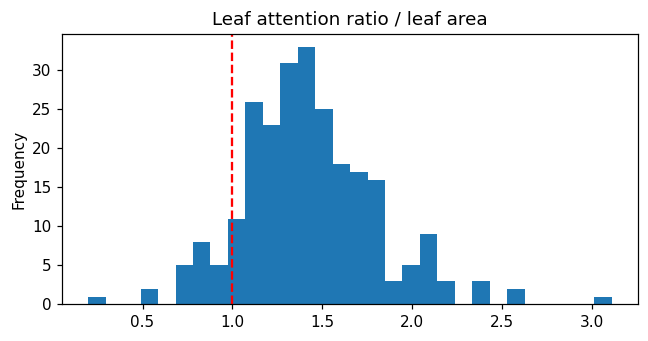

In [9]:
rows = []
for i in rng.choice(np.where(y_true != bg_id)[0], size=min(250, N), replace=False):
    cam, _, _ = gradcam(arrs[i], class_idx=int(y_pred[i]))
    _, cam_up = overlay(arrs[i], cam)
    m = leaf_mask(arrs[i])
    area = m.mean()
    if not (0.1 < area < 0.95) or cam_up.sum() == 0:
        continue
    inside = cam_up[m].sum() / cam_up.sum()
    rows.append({"leaf_area": area, "cam_on_leaf": inside, "ratio": inside / area,
                 "correct": bool(y_pred[i] == y_true[i])})

df_focus = pd.DataFrame(rows)
print(f"Analyzed images: {len(df_focus)}")
print(df_focus[["leaf_area", "cam_on_leaf", "ratio"]].describe().round(3))
print()
print(df_focus.groupby("correct")["ratio"].agg(["count", "mean", "median"]).round(3))

df_focus["ratio"].plot.hist(bins=30, figsize=(6, 3.2), title="Leaf attention ratio / leaf area")
plt.axvline(1, color="red", linestyle="--")
plt.tight_layout()
plt.show()

## 4. Robustness test with images from other sources

**Default source: PlantDoc** (leaves cropped from image search engines, CC BY 4.0 license). It shares several crops and diseases with PlantVillage, but with very different backgrounds, lighting, and quality. Images are read from the local folder `data/plantdoc` if it exists, or downloaded from Hugging Face (`Project-AgML/plant_doc_classification`).

For comparison, each PlantDoc class is manually mapped to its PlantVillage equivalent (`CLASS_MAP`). All 28 PlantDoc classes were mapped; this is a manual judgment call that may contain errors (for example, the pepper "leaf spot" was assigned to bacterial spot). The code also supports your own photos (`SOURCE = "folder"`), organized in `data/external/<PlantVillageClassName>/`; this option is not used in the reported results.

In [10]:
SOURCE = "plantdoc"   # "plantdoc" | "folder"
EXT_FOLDER = os.path.join(ROOT, "data", "external")

# Equivalencia entre clases de PlantDoc (nombres en minúsculas) y de PlantVillage
CLASS_MAP = {
    "apple scab leaf": "Apple___Apple_scab",
    "apple rust leaf": "Apple___Cedar_apple_rust",
    "apple leaf": "Apple___healthy",
    "bell_pepper leaf spot": "Pepper,_bell___Bacterial_spot",
    "bell_pepper leaf": "Pepper,_bell___healthy",
    "blueberry leaf": "Blueberry___healthy",
    "cherry leaf": "Cherry___healthy",
    "corn gray leaf spot": "Corn___Cercospora_leaf_spot Gray_leaf_spot",
    "corn leaf blight": "Corn___Northern_Leaf_Blight",
    "corn rust leaf": "Corn___Common_rust",
    "peach leaf": "Peach___healthy",
    "potato leaf early blight": "Potato___Early_blight",
    "potato leaf late blight": "Potato___Late_blight",
    "raspberry leaf": "Raspberry___healthy",
    "soyabean leaf": "Soybean___healthy",
    "squash powdery mildew leaf": "Squash___Powdery_mildew",
    "strawberry leaf": "Strawberry___healthy",
    "tomato early blight leaf": "Tomato___Early_blight",
    "tomato septoria leaf spot": "Tomato___Septoria_leaf_spot",
    "tomato leaf": "Tomato___healthy",
    "tomato leaf bacterial spot": "Tomato___Bacterial_spot",
    "tomato leaf late blight": "Tomato___Late_blight",
    "tomato leaf mosaic virus": "Tomato___Tomato_mosaic_virus",
    "tomato leaf yellow virus": "Tomato___Tomato_Yellow_Leaf_Curl_Virus",
    "tomato mold leaf": "Tomato___Leaf_Mold",
    "tomato two spotted spider mites leaf": "Tomato___Spider_mites Two-spotted_spider_mite",
    "grape leaf": "Grape___healthy",
    "grape leaf black rot": "Grape___Black_rot",
}

In [21]:
ext_pil, ext_y, ext_src = [], [], []

if SOURCE == "plantdoc":
    from datasets import load_dataset, concatenate_datasets
    pdoc_local = os.path.join(ROOT, "data", "plantdoc")
    pdoc = load_dataset(pdoc_local if os.path.isdir(pdoc_local) else "Project-AgML/plant_doc_classification")
    pdoc_all = concatenate_datasets([pdoc[s] for s in pdoc.keys()])
    pdoc_names = pdoc_all.features["label"].names
    print("PlantDoc classes:", len(pdoc_names), "| images:", len(pdoc_all))

    mapped = {i: name2id.get(CLASS_MAP.get(n.strip().lower())) for i, n in enumerate(pdoc_names)}
    print("\nPlantDoc classes with no PlantVillage equivalent (excluded):")
    for i, n in enumerate(pdoc_names):
        if mapped[i] is None:
            print("  -", n)

    for ex in pdoc_all:
        t = mapped[ex["label"]]
        if t is not None:
            ext_pil.append(ex["image"])
            ext_y.append(t)
            ext_src.append(pdoc_names[ex["label"]])

elif SOURCE == "folder":
    for cname in sorted(os.listdir(EXT_FOLDER)):
        if cname not in name2id:
            print("Ignored folder (does not match a PlantVillage class):", cname)
            continue
        for fn in os.listdir(os.path.join(EXT_FOLDER, cname)):
            if fn.lower().endswith((".jpg", ".jpeg", ".png")):
                ext_pil.append(Image.open(os.path.join(EXT_FOLDER, cname, fn)))
                ext_y.append(name2id[cname])
                ext_src.append(cname)

ext_y = np.array(ext_y)
ext_arrs = np.stack([to_input(im) for im in ext_pil])
print("\nExternal images used:", len(ext_arrs), "| classes present:", len(set(ext_y.tolist())))

PlantDoc classes: 28 | images: 2569

PlantDoc classes with no PlantVillage equivalent (excluded):

External images used: 2569 | classes present: 28


### 4.1 Out-of-distribution metrics

PlantDoc images are predicted with the unmodified model, and the following are reported:

- **Top-1 accuracy:** the class with the highest probability is the correct one.
- **Top-3 accuracy:** the correct class is among the three with the highest probability.
- **Macro F1:** average of the F1 scores of the classes present in PlantDoc.

Below are shown the per-class accuracy, the most frequent confusions, and which classes the model predicts most often.

In [12]:
ext_probs = full_model.predict(ext_arrs.astype(np.float32), batch_size=64, verbose=0)
ext_pred = ext_probs.argmax(1)

top1 = float((ext_pred == ext_y).mean())
top3 = float(np.mean([ext_y[i] in np.argsort(ext_probs[i])[-3:] for i in range(len(ext_y))]))
labels_present = sorted(set(ext_y.tolist()))
f1_ext = f1_score(ext_y, ext_pred, labels=labels_present, average="macro", zero_division=0)

print(f"Accuracy top-1:            {top1:.3f}")
print(f"Accuracy top-3:            {top3:.3f}")
print(f"F1 macro (classes present): {f1_ext:.3f}")
print(f"PlantVillage reference (test, notebook 03): accuracy 0.987 | F1 macro 0.982")

Accuracy top-1:            0.088
Accuracy top-3:            0.229
F1 macro (classes present): 0.095
PlantVillage reference (test, notebook 03): accuracy 0.987 | F1 macro 0.982


In [13]:
per_class = (
    pd.DataFrame({"class": [id2name[i] for i in ext_y], "ok": ext_pred == ext_y})
    .groupby("class")["ok"].agg(["mean", "count"])
    .rename(columns={"mean": "accuracy", "count": "n"})
    .sort_values("accuracy")
)
per_class.round(3)

,accuracy,n
class,,
Apple___Cedar_apple_rust,0.000,88
Grape___Black_rot,0.000,64
Tomato___Tomato_mosaic_virus,0.000,54
Tomato___Leaf_Mold,0.000,91
Tomato___Spider_mites Two-spotted_spider_mite,0.000,2
Tomato___Tomato_Yellow_Leaf_Curl_Virus,0.000,75
Tomato___Bacterial_spot,0.009,110
Soybean___healthy,0.015,65
Tomato___healthy,0.016,63


In [14]:
conf = pd.Series(
    [(id2name[a], id2name[b]) for a, b in zip(ext_y, ext_pred) if a != b]
).value_counts().head(10)
pd.DataFrame({"number": conf.values, "real → predicted": [f"{a}  →  {b}" for a, b in conf.index]})

,number,real → predicted
0,99,Raspberry___healthy → Background_without_leaves
1,90,Blueberry___healthy → Background_without_leaves
2,88,Peach___healthy → Background_without_leaves
3,83,Strawberry___healthy → Background_without_le...
4,71,Tomato___Septoria_leaf_spot → Background_wit...
5,65,Apple___healthy → Background_without_leaves
6,62,Corn___Northern_Leaf_Blight → Background_wit...
7,56,Tomato___Bacterial_spot → Background_without...
8,54,Tomato___Tomato_Yellow_Leaf_Curl_Virus → Bac...
9,52,Tomato___healthy → Background_without_leaves


In [15]:
dist = pd.Series([id2name[i] for i in ext_pred]).value_counts().head(8)
print("Most predicted classes on the external images:")
print(dist)
print("\nPredicted as background (no leaf):", int((ext_pred == bg_id).sum()))

Most predicted classes on the external images:
Background_without_leaves                     1397
Strawberry___Leaf_scorch                       202
Tomato___Late_blight                           191
Corn___Cercospora_leaf_spot Gray_leaf_spot     105
Corn___healthy                                  78
Corn___Northern_Leaf_Blight                     75
Tomato___Early_blight                           68
Pepper,_bell___Bacterial_spot                   49
Name: count, dtype: int64

Predicted as background (no leaf): 1397


### 4.1.1 Diagnostics: is the failure explained by the background class or by preprocessing?

Since more than half of the images are predicted as `Background_without_leaves`, two possible explanations are tested without retraining the model:

1. **Ignoring the background class when predicting:** its probability is zeroed out and the prediction is chosen among the remaining 38 classes.
2. **Centered square crop** instead of stretching each image to 224x224, because PlantDoc images are not square.

In [16]:
# Diagnostic 1: ignore the background class when predicting
p = ext_probs.copy()
p[:, bg_id] = 0
p /= p.sum(1, keepdims=True)
pred_nb = p.argmax(1)

top1_nb = float((pred_nb == ext_y).mean())
top3_nb = float(np.mean([ext_y[i] in np.argsort(p[i])[-3:] for i in range(len(ext_y))]))
f1_nb = f1_score(ext_y, pred_nb, labels=labels_present, average="macro", zero_division=0)
print(f"Without the background class -> top-1 {top1_nb:.3f} | top-3 {top3_nb:.3f} | F1 macro {f1_nb:.3f}")

Without the background class -> top-1 0.123 | top-3 0.278 | F1 macro 0.117


In [17]:
# Diagnóstico 2: recorte cuadrado centrado en lugar de estirar la imagen
def to_input_crop(pil_img):
    im = pil_img.convert("RGB")
    s = min(im.size)
    left, top = (im.size[0] - s) // 2, (im.size[1] - s) // 2
    return np.asarray(im.crop((left, top, left + s, top + s)).resize(IMG_SIZE), dtype=np.uint8)

arrs_crop = np.stack([to_input_crop(im) for im in ext_pil])
probs_crop = full_model.predict(arrs_crop.astype(np.float32), batch_size=64, verbose=0)
pred_crop = probs_crop.argmax(1)
print(f"Square crop -> top-1 {(pred_crop == ext_y).mean():.3f} | "
      f"Predicted as background: {int((pred_crop == bg_id).sum())}")

Square crop -> top-1 0.104 | Predicted as background: 1293


### 4.2 Is the model's confidence useful for detecting errors?

Confidence is the maximum probability the model assigns. If the model were reliable out of distribution, its errors would have low confidence and could be rejected. We measure how much accuracy is obtained if only predictions above a confidence threshold are accepted, and what fraction of the images (coverage) is accepted.

In [18]:
conf_max = ext_probs.max(1)
correct = ext_pred == ext_y
print(f"Mean confidence — correct predictions: {conf_max[correct].mean():.3f} | errores: {conf_max[~correct].mean():.3f}")

rows = []
for thr in [0.0, 0.5, 0.7, 0.9, 0.95, 0.99]:
    m = conf_max >= thr
    rows.append({"threshold": thr, "coverage": m.mean(),
                 "accuracy_accepted": correct[m].mean() if m.any() else np.nan})
pd.DataFrame(rows).round(3)

Mean confidence — correct predictions: 0.894 | errores: 0.908


,threshold,coverage,accuracy_accepted
0,0.00,1.000,0.088
1,0.50,0.976,0.087
2,0.70,0.866,0.086
3,0.90,0.725,0.084
4,0.95,0.659,0.082
5,0.99,0.529,0.075


### 4.3 Grad-CAM on external images

Heatmaps of six randomly chosen correct predictions and six errors from PlantDoc, computed for the predicted class. They show whether the model focuses on the lesions when it is right and what it does when it is wrong.

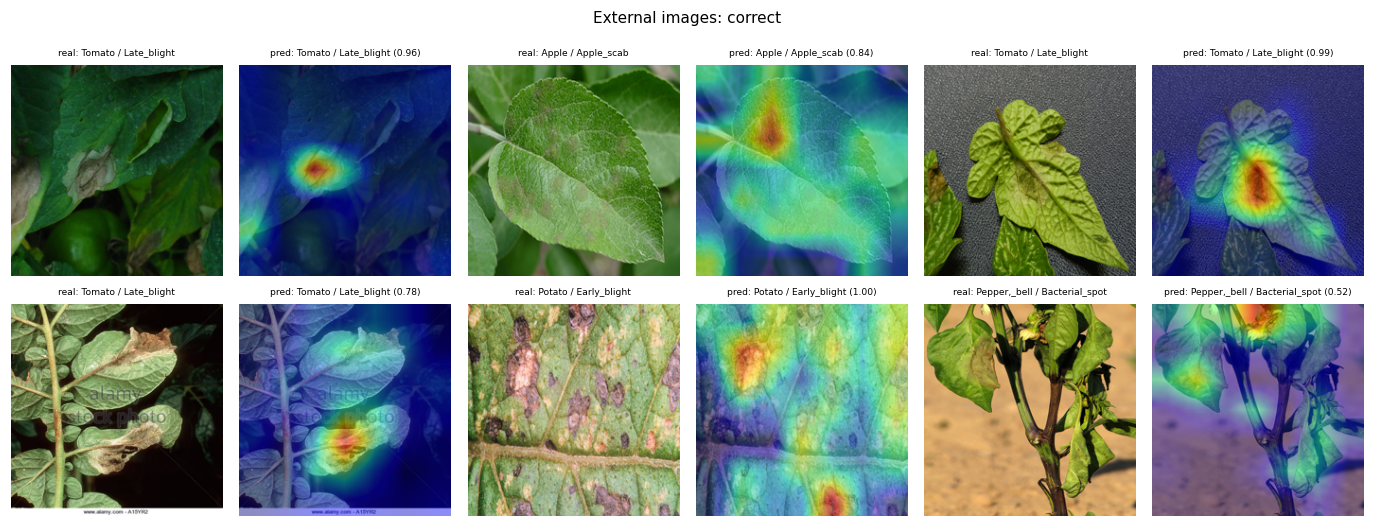

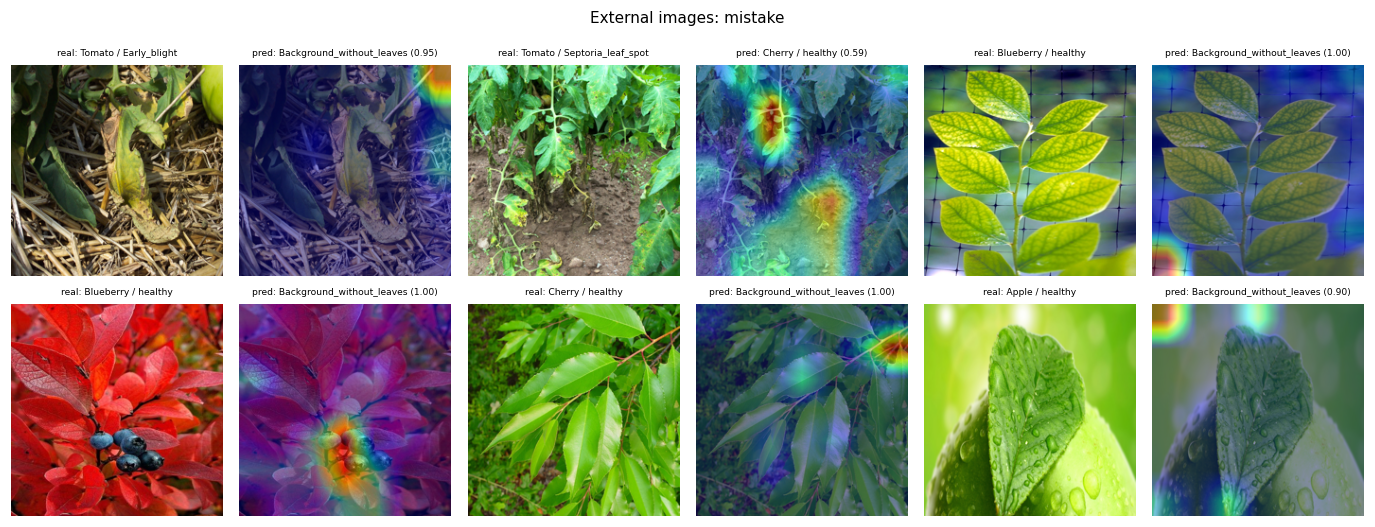

In [19]:
ext_ok = np.where(ext_pred == ext_y)[0]
ext_bad = np.where(ext_pred != ext_y)[0]
if len(ext_ok) >= 6:
    show_cams(rng.choice(ext_ok, size=6, replace=False), ext_arrs, ext_y, ext_pred, ext_probs,
              title="External images: correct")
if len(ext_bad) >= 6:
    show_cams(rng.choice(ext_bad, size=6, replace=False), ext_arrs, ext_y, ext_pred, ext_probs,
              title="External images: mistake")

## 5. Saving results

The robustness metrics and the attention ratio are saved to `reports/robustez_plantdoc.json`. This report does not correspond to a training experiment, so it does not appear in the comparison tables of notebooks 02 and 03.

In [ ]:
os.makedirs(os.path.join(ROOT, "reports"), exist_ok=True)
results = {
    "model": MODEL_NAME,
    "external_source": SOURCE,
    "n_external_images": int(len(ext_y)),
    "n_external_classes": int(len(labels_present)),
    "accuracy_top1": round(top1, 4),
    "accuracy_top3": round(top3, 4),
    "f1_macro": round(float(f1_ext), 4),
    "reference_plantvillage_accuracy": 0.987,
    "reference_plantvillage_f1_macro": 0.982,
    "ratio_attention_leaf_median": round(float(df_focus["ratio"].median()), 3),
}
out = os.path.join(ROOT, "reports", f"robustez_{SOURCE}.json")
with open(out, "w", encoding="utf-8") as f:
    json.dump(results, f, ensure_ascii=False, indent=2)
print("Saved in", out)
results

Saved in c:\Users\Carlos\Desktop\Python-Prep\proyecto_vision_plantvillage\reports\robustez_plantdoc.json


{'modelo': 'tl_mobilenetv3small_224_cw0.5_full_full.keras',
 'external_source': 'plantdoc',
 'n_external_images': 2569,
 'n_external_classes': 28,
 'accuracy_top1': 0.0876,
 'accuracy_top3': 0.2289,
 'f1_macro': 0.0954,
 'reference_plantvillage_accuracy': 0.987,
 'reference_plantvillage_f1_macro': 0.982,
 'ratio_attention_leaf_median': 1.403}

## 6. Conclusions

- **Model analyzed:** the final configuration from notebook 03 (accuracy 0.987 and macro F1 0.982 on the PlantVillage test set; accuracy 0.980 on the 400-image sample used here).
- **Grad-CAM on PlantVillage:** computed on the logit, the map falls on the leaf (sometimes on lesions, sometimes on nearby healthy tissue) and not on the background. With an approximate leaf mask based on saturation, the median attention ratio is 1.40 over 247 images. Only 4 of them are errors, so correct predictions and errors cannot be compared.
- **Robustness:** on PlantDoc (2,569 images, 28 mapped classes) the model drops to a top-1 accuracy of 0.088, top-3 of 0.229, and macro F1 of 0.095, versus 0.987 and 0.982 on PlantVillage.
- **Which classes break:** almost all of them. The best is `Tomato___Late_blight` (0.459) and the healthy classes do not exceed 0.06. 54% of the images (1,397) are predicted as `Background_without_leaves`: the model treats field scenes as "no leaf". Some classes have very few images in PlantDoc (tomato mites have only 2), so their per-class accuracy is not informative.
- **Diagnostics (section 4.1.1):** ignoring the background class when predicting raises top-1 only to 0.123; using a square crop instead of stretching the image leaves it at 0.104. The failure is not explained by those two factors.
- **Confidence:** the mean confidence is 0.894 for correct predictions and 0.908 for errors. Accepting only predictions with confidence ≥ 0.99 (53% coverage), accuracy remains at 0.075. The softmax probability is not useful for rejecting out-of-distribution inputs.
- **Grad-CAM on PlantDoc:** on correct predictions, the map falls on the lesions; on errors, one or two scattered blobs appear, unrelated to the lesions.
- **Interpretation:** the collapse looks like a general domain shift (lighting, scale, backgrounds, quality) and not a problem of attention to the background. This is a hypothesis: it was not tested.
- **Limitations:** manual class mapping between datasets, label noise in PlantDoc, classes with very few images, heuristic leaf mask, low-resolution maps (7x7), visual review of Grad-CAM on a small sample, and a PlantVillage split not grouped by leaf.
- **Next steps:** strong augmentation, fine-tuning, incorporating part of the field images into training, and an out-of-distribution input detection method.